# 02 - Análise exploratória

**Pergunta:** quais características influenciam a popularidade de um jogo na Steam, e dá para prever essa popularidade com AM?

**Alvo:** `peak_ccu` (pico de jogadores simultâneos).

**Gera:** `data/processed/features.csv` (tabela limpa, usada na etapa de modelagem).

In [26]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

dataset = pd.read_parquet("../data/clean/jogos_limpos.parquet")


### 2.1 -  Variável alvo: `peak_ccu`

In [27]:
p = dataset["peak_ccu"]
print(p.describe(percentiles=[.5,.75,.9,.95,.99,.999]).round(1).to_string)
print(f"\n== 0: {(p == 0).mean():.1%} | <= 5: {(p <= 5).mean():.1%} | >= 1000: {(p >= 1000).sum()} jogos")

<bound method Series.to_string of count      83646.0
mean          99.3
std         5914.5
min            0.0
50%            0.0
75%            0.0
90%            4.0
95%           21.0
99%          473.8
99.9%      15462.9
max      1362469.0
Name: peak_ccu, dtype: float64>

== 0: 77.7% | <= 5: 91.2% | >= 1000: 528 jogos


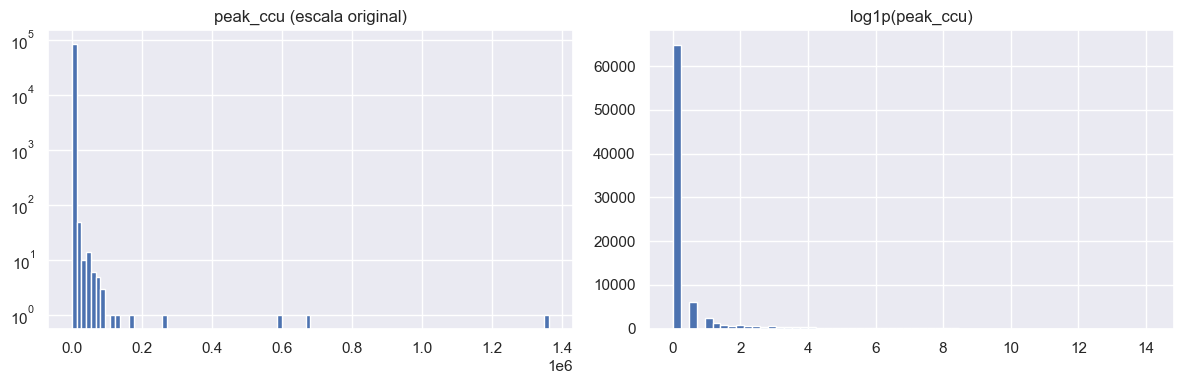

In [28]:


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(p, bins=100); ax[0].set_title("peak_ccu (escala original)"); ax[0].set_yscale("log")
ax[1].hist(np.log1p(p), bins=60); ax[1].set_title("log1p(peak_ccu)")
plt.tight_layout(); plt.show()

A distribuição é extremamente assimétrica: a mediana é 0 e poucos jogos passam de milhares de jogadores. Regressão no valor bruto seria dominada por poucos outliers.
Por isso o alvo da modelagem será uma **classificação em faixas**, com regressão em `log1p(peak_ccu)` como análise complementar.

           jogos     %
faixa_ccu             
0          64966  77.7
1-20       14438  17.3
21-500      3435   4.1
500+         807   1.0


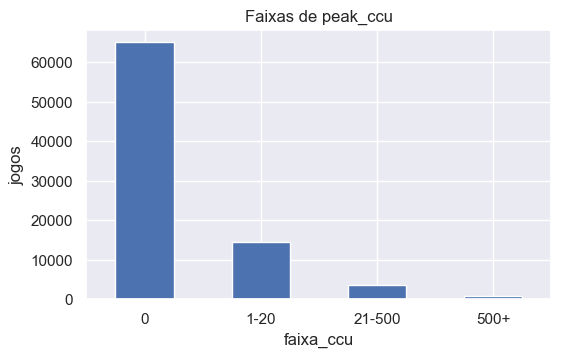

In [29]:
bins = [-1,0,20,500,np.inf]
labels = ["0", "1-20", "21-500", "500+"]
dataset["faixa_ccu"] = pd.cut(dataset.peak_ccu, bins=bins, labels=labels)
dataset["log_ccu"] = np.log1p(dataset.peak_ccu)
cont = dataset.faixa_ccu.value_counts().reindex(labels)
print(pd.DataFrame({"jogos": cont, "%": (cont / len(dataset) * 100).round(1)}))
ax = cont.plot(kind="bar", figsize=(6, 3.5), rot=0); ax.set_ylabel("jogos"); ax.set_title("Faixas de peak_ccu")
plt.show()





As classes são muito desbalanceadas (`0` domina e `500+` é cerca de 1%). Na modelagem: split estratificado, `class_weight` e F1-macro como métrica principal (acurácia sozinha seria enganosa).

### 2.2 - Engenharia de variáveis
Só características conhecidas **no lançamento** do jogo. A idade do jogo é calculada até a data de coleta (maio/2024), porque o `peak_ccu` é um retrato dessa data.

In [ ]:
def parse_list(x):
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, (list, dict)) else []
    except Exception:
        return []

DATA_COLETA = pd.Timestamp("2024-05-31")
listas = {c: dataset[c].map(parse_list) for c in ["supported_languages", "full_audio_languages", "categories", "genres", "tags", "developers", "publishers"]}

X = pd.DataFrame({"AppID": dataset.AppID})
X["preco"] = dataset.price
X["gratis"] = (dataset.price == 0).astype(int)
X["idade_anos"] = (DATA_COLETA - dataset.release_date).dt.days / 365.25
X["ano_lancamento"] = dataset.release_date.dt.year
X["mes_lancamento"] = dataset.release_date.dt.month
X["idade_minima"] = dataset.required_age
X["dlc"] = dataset.dlc_count
X["conquistas"] = dataset.achievements
X["windows"] = dataset.windows.astype(int); X["mac"] = dataset.mac.astype(int); X["linux"] = dataset.linux.astype(int)
X["n_idiomas"] = listas["supported_languages"].map(len)
X["tem_dublagem"] = (listas["full_audio_languages"].map(len) > 0).astype(int)
X["n_categorias"] = listas["categories"].map(len)
X["n_generos"] = listas["genres"].map(len)
X["n_tags"] = listas["tags"].map(len)
X["n_screenshots"] = dataset.screenshots.map(parse_list).map(len)
X["n_videos"] = dataset.movies.map(parse_list).map(len)
X["tem_website"] = dataset.website.notna().astype(int)
X["tem_suporte"] = (dataset.support_url.notna() | dataset.support_email.notna()).astype(int)
X["tem_metacritic"] = dataset.metacritic_score.notna().astype(int)
X["n_devs"] = listas["developers"].map(len)
X["autopublicado"] = [int(set(d) == set(p) and len(d) > 0) for d, p in zip(listas["developers"], listas["publishers"])]
X["log_ccu"] = dataset.log_ccu
X["faixa_ccu"] = dataset.faixa_ccu
print(X.shape)
X.describe().T[["mean", "50%", "max"]].round(2)

(83646, 23)


## 2.3 - Distribuição e outliers das variáveis númericas


,outliers_IQR,max,p99,% outliers
price,4146,999.980000,44.990000,5.0
idade_anos,1180,26.936986,13.700137,1.4
dlc_count,13475,3165.000000,7.550000,16.1
achievements,5195,9821.000000,101.000000,6.2
n_idiomas,11284,103.000000,103.000000,13.5
n_categorias,4793,23.000000,13.000000,5.7
n_generos,399,19.000000,7.000000,0.5
n_tags,0,21.000000,20.000000,0.0


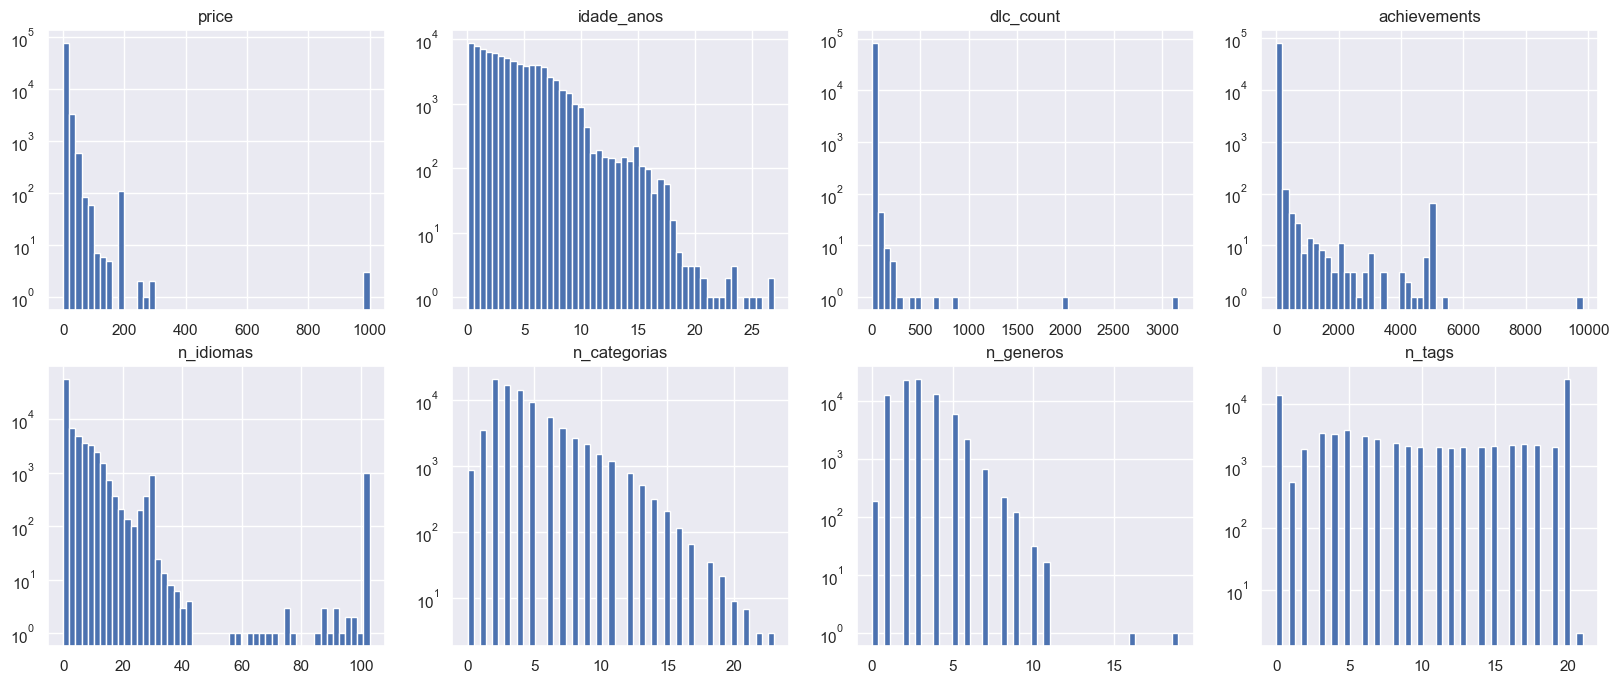

In [ ]:
num = ["preco", "idade_anos", "dlc", "conquistas", "n_idiomas", "n_categorias", "n_generos", "n_tags", "n_screenshots", "n_videos"]
fig, axes = plt.subplots(2 ,4 ,figsize = (20,8))
for a, c in zip(axes.ravel(), num):
    a.hist(histograma[c].dropna(),bins=50)
    a.set_title(c) 
    a.set_yscale("log")

def n_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

out = pd.DataFrame({"outliers_IQR": {c: n_outliers(histograma[c].dropna()) for c in num},
                    "max": histograma[num].max(),
                    "p99": histograma[num].quantile(.99)})
out["% outliers"] = (out.outliers_IQR / len(histograma) * 100).round(1)


out

Quase todas as variáveis numéricas são assimétricas à direita. O IQR funciona mal com muitos zeros (em `dlc_count` o IQR é 0, então qualquer DLC vira "outlier"), então a contagem superestima. Os valores extremos são dados reais, não erros de coleta, e por isso não são removidos: os 5 jogos mais caros (US$ 300 a 1.000), por exemplo, têm 0 jogadores no pico. Nas variáveis de cauda longa aplica-se `log1p` antes da regressão logística e da MLP, e os modelos de árvore dispensam isso. Em `n_idiomas`, 985 jogos listam 103 idiomas e 91% deles têm 0 jogadores no pico, então foi criada a flag `todas_linguas`.

## 2.4- Relação das variáveis com a popularidade

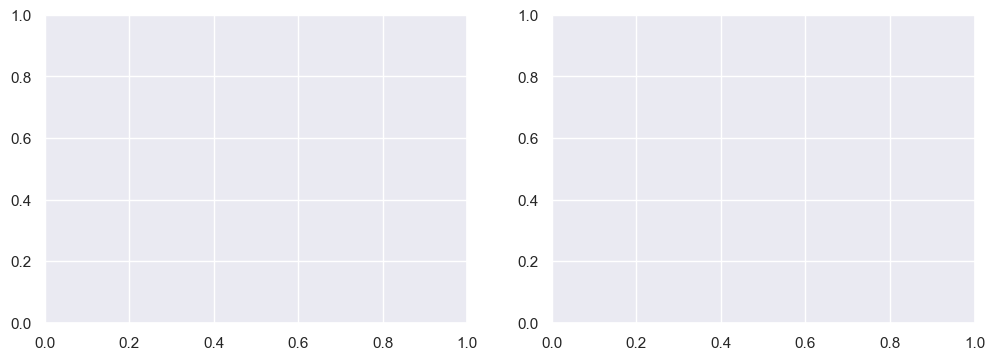

In [38]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
por_ano = dataset.groupby("release_date")